<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerID          2000 non-null   str    
 1   Name                2000 non-null   str    
 2   Age                 2000 non-null   int64  
 3   Gender              2000 non-null   str    
 4   Annual_Income       2000 non-null   int64  
 5   Spending_Score      2000 non-null   int64  
 6   Membership_Level    2000 non-null   str    
 7   Purchase_Frequency  2000 non-null   float64
 8   Churn_Status        2000 non-null   int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 140.8 KB
Пропущенные значения:
 CustomerID            0
Name                  0
Age                   0
Gender                0
Annual_Income         0
Spending_Score        0
Membership_Level      0
Purchase_Frequency    0
Churn_Status          0
dtype: int64


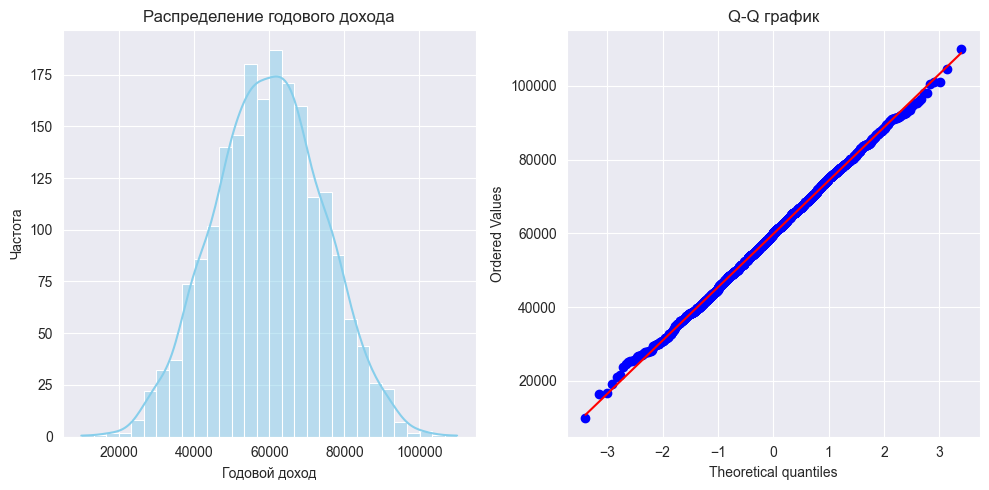

Тест Шапиро-Уилка: статистика=0.9993, p-value=6.3626e-01
p-value > 0.05 -> Данные распределены нормально
Средние значения годового дохода по полу:
                 mean   median  count
Gender                              
Female  60031.627530  60036.5    988
Male    59671.703557  59961.0   1012


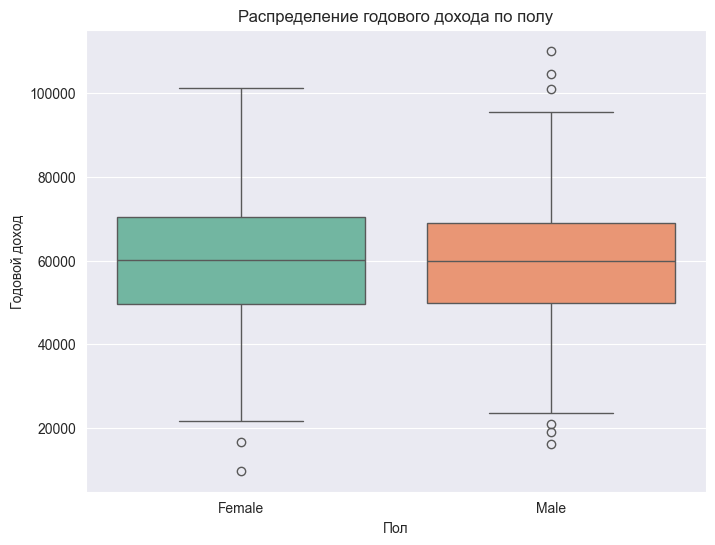

Средний доход мужчин: 59671.70
Средний доход женщин: 60031.63
t-тест: статистика=-0.5568, p-value=5.7775e-01
Нет статистически значимых различий в доходах мужчин и женщин

ЗАДАНИЕ 2: ДИСПЕРСИОННЫЙ АНАЛИЗ
Уровни членства: <StringArray>
['Gold', 'Basic', 'Silver', 'Platinum']
Length: 4, dtype: str


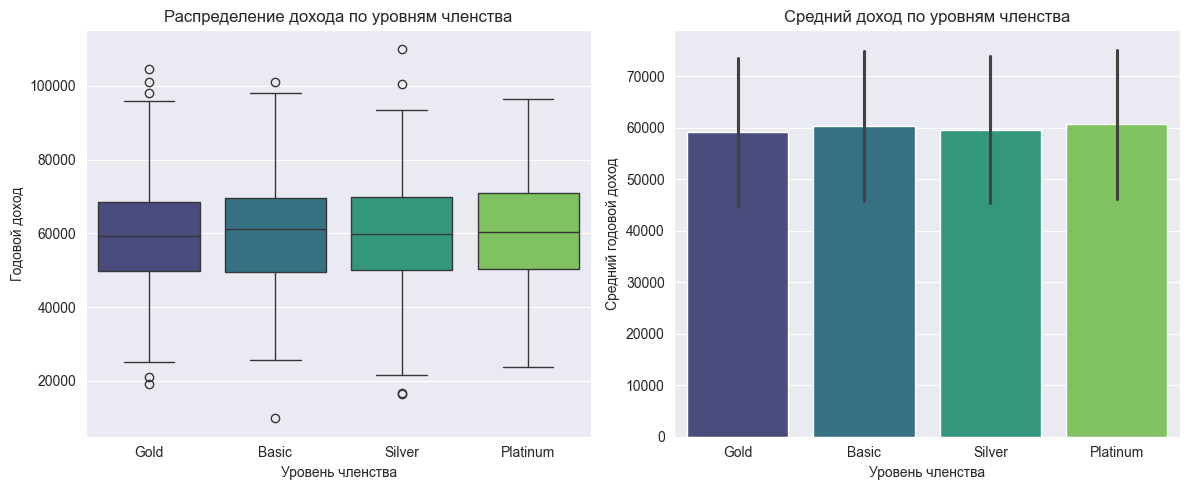

Средний доход по уровням членства:
                           mean           std  count
Membership_Level                                   
Basic             60337.556314  14652.186755    586
Gold              59110.209830  14450.453845    529
Platinum          60687.835616  14469.236615    292
Silver            59613.920742  14240.143088    593
Тест Левена (равенство дисперсий): статистика=0.1796, p-value=9.1028e-01
ANOVA: F-статистика=1.0644, p-value=3.6303e-01
Нет статистически значимых различий в доходе между уровнями членства


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

FILE_PATH = "data/customer_data_with_churn.csv"
ALPHA = 0.05

df = pd.read_csv(FILE_PATH)
df.head()

df.info()
df.describe()

print("Пропущенные значения:\n", df.isnull().sum())

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Annual_Income'], bins=30, kde=True, color='skyblue')
plt.title('Распределение годового дохода')
plt.xlabel('Годовой доход')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
stats.probplot(df['Annual_Income'], dist="norm", plot=plt)
plt.title('Q-Q график')

plt.tight_layout()
plt.show()

stat, p_value = stats.shapiro(df['Annual_Income'].dropna())
print(f"Тест Шапиро-Уилка: статистика={stat:.4f}, p-value={p_value:.4e}")

if p_value > ALPHA:
    print("p-value > 0.05 -> Данные распределены нормально")
else:
    print("p-value <= 0.05 -> Данные НЕ распределены нормально")

mean_income_by_gender = df.groupby('Gender')['Annual_Income'].agg(['mean', 'median', 'count'])
print("Средние значения годового дохода по полу:\n", mean_income_by_gender)

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Gender', y='Annual_Income', palette='Set2')
plt.title('Распределение годового дохода по полу')
plt.xlabel('Пол')
plt.ylabel('Годовой доход')
plt.show()

male_income = df[df['Gender'] == 'Male']['Annual_Income'].dropna()
female_income = df[df['Gender'] == 'Female']['Annual_Income'].dropna()

print(f"Средний доход мужчин: {male_income.mean():.2f}")
print(f"Средний доход женщин: {female_income.mean():.2f}")

if p_value > ALPHA:
    t_stat, t_p = stats.ttest_ind(male_income, female_income)
    print(f"t-тест: статистика={t_stat:.4f}, p-value={t_p:.4e}")
else:
    u_stat, u_p = stats.mannwhitneyu(male_income, female_income, alternative='two-sided')
    print(f"U-тест Манна-Уитни: статистика={u_stat:.4f}, p-value={u_p:.4e}")
    t_p = u_p

if t_p > ALPHA:
    print("Нет статистически значимых различий в доходах мужчин и женщин")
else:
    print("Есть статистически значимые различия в доходах мужчин и женщин")

print("\n" + "="*50)
print("ЗАДАНИЕ 2: ДИСПЕРСИОННЫЙ АНАЛИЗ")
print("="*50)

membership_levels = df['Membership_Level'].unique()
print(f"Уровни членства: {membership_levels}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='Membership_Level', y='Annual_Income', palette='viridis')
plt.title('Распределение дохода по уровням членства')
plt.xlabel('Уровень членства')
plt.ylabel('Годовой доход')

plt.subplot(1, 2, 2)
sns.barplot(data=df, x='Membership_Level', y='Annual_Income', estimator=np.mean, errorbar='sd', palette='viridis')
plt.title('Средний доход по уровням членства')
plt.xlabel('Уровень членства')
plt.ylabel('Средний годовой доход')

plt.tight_layout()
plt.show()

mean_by_membership = df.groupby('Membership_Level')['Annual_Income'].agg(['mean', 'std', 'count'])
print("Средний доход по уровням членства:\n", mean_by_membership)

groups = [df[df['Membership_Level'] == level]['Annual_Income'].dropna().values
          for level in membership_levels]

levene_stat, levene_p = stats.levene(*groups)
print(f"Тест Левена (равенство дисперсий): статистика={levene_stat:.4f}, p-value={levene_p:.4e}")

f_stat, anova_p = stats.f_oneway(*groups)
print(f"ANOVA: F-статистика={f_stat:.4f}, p-value={anova_p:.4e}")

if anova_p > ALPHA:
    print("Нет статистически значимых различий в доходе между уровнями членства")
else:
    print("Есть статистически значимые различия в доходе между уровнями членства")

if anova_p <= ALPHA:
    print("\nPost-hoc анализ (Tukey HSD):")
    from statsmodels.stats.multicomp import pairwise_tukeyhsd

    tukey_data = df[['Annual_Income', 'Membership_Level']].dropna()
    tukey_result = pairwise_tukeyhsd(tukey_data['Annual_Income'],
                                     tukey_data['Membership_Level'],
                                     alpha=ALPHA)
    print(tukey_result)

    plt.figure(figsize=(10, 6))
    tukey_result.plot_simultaneous()
    plt.title('Tukey HSD: попарное сравнение уровней членства')
    plt.xlabel('Разница в среднем доходе')
    plt.show()